# Piezas movidas por día por área — API LISA (SGA)

Serie diaria del volumen movido en cada área del almacén, tomando **cada endpoint SGA como un área**:

| Endpoint | Área | Campo de piezas | Métrica graficada |
|---|---|---|---|
| `SGAENTRADAS2` | RECIBO | `cantidad_presentacion` | **piezas/día** |
| `SGACOLOCACION2` | UBICACIONES | `unidades1` | **piezas/día** |
| `SGAPREPARACION` | SURTIDO | `cantidad_unidad1_ped` | **piezas/día** (pedidas, proxy) |
| `SGAEMBALAJE2` | VERIFICACIÓN | `cantidad_presentacion` | **piezas/día** |

> **Cambios del API verificados (21-jul-2026, contrato `edisa.json`):**
>
> - `sga_entradas` (nivel tarea) sigue sin cantidades, pero **`sga_entradas_2`**
>   (nivel línea: artículo, lote, palet) trae `cantidad_presentacion` → RECIBO grafica
>   **piezas reales**, no el proxy de tareas.
> - Apareció **`sga_embalaje_2`** (nivel línea: artículo, lote) con `cantidad_presentacion`
>   → VERIFICACIÓN ya grafica **piezas reales**, no el proxy de tareas/día. Cobertura desde
>   el 23-feb-2026 (el v1 arrancaba el 09-feb).
> - `sga_preparacion_2` **sigue congelado**: pidiendo toda la historia solo devuelve
>   09-feb → 10-abr con las mismas sumas que a inicios de julio (`cantidad_p` total
>   2,487,163), igual que `cantidad_unidad1_res`/`cantidad_facturada` del v1 → SURTIDO
>   permanece en `sga_preparacion` v1 graficando **piezas pedidas** (`cantidad_unidad1_ped`)
>   como proxy de movidas (en el periodo sano, ped ≈ 1.13× res por los surtidos parciales).

Notas de importación:

- Las fechas de **petición** van en ISO `AAAA-MM-DD`: `dd/mm/aaaa` devuelve HTTP 400
  (ORA-01830) y `dd/mm/aa` se malinterpreta **en silencio** como año 1 (trae toda la historia).
- Las fechas de **respuesta** son mixtas: `entradas(_2)`, `colocacion_2` y `embalaje_2` en
  `dd/mm/aaaa`; `preparacion(_2)` y `embalaje` en ISO 8601 — `parsea_fechas()` resuelve por
  prefijo para que `dayfirst=True` no voltee las ISO (`2026-03-12` es 12-mar, no 3-dic).
- Los filtros de fecha actúan como **cota inferior**, salvo `sga_entradas_2` y
  `sga_embalaje_2`, que **ignoran** el filtro y devuelven toda la historia (aquí no estorba:
  pedimos todo de cualquier forma).
- La base temporal es `fecha_inicio` (inicio de la tarea en el handheld, convención del repo).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

from lisa_client import LisaClient

ALMACEN = "5460D"
FECHA_DESDE = "2025-01-01"  # cota inferior (formato ISO del API): trae toda la historia

# sga_preparacion (nivel línea) devuelve ~72k registros: 30s de timeout no alcanzan
client = LisaClient(timeout=300)

## 1. Importación desde el API

Los registros vienen en `registros.reg` (un `dict` cuando hay un solo registro, una lista en otro caso).

In [2]:
def a_dataframe(respuesta: dict) -> pd.DataFrame:
    """Convierte la respuesta del API (registros.reg) en un DataFrame."""
    registros = (respuesta.get("registros") or {}).get("reg") or []
    if isinstance(registros, dict):  # un solo registro llega como dict
        registros = [registros]
    return pd.DataFrame(registros)


df_entradas = a_dataframe(client.entradas_almacen_2(fecha_gen=FECHA_DESDE, almacen=ALMACEN))
df_colocacion = a_dataframe(client.colocacion_2(fecha_gen=FECHA_DESDE, almacen=ALMACEN))
df_preparacion = a_dataframe(client.preparacion(fecha_gen=FECHA_DESDE, almacen=ALMACEN))
df_embalaje = a_dataframe(client.embalaje_2(fecha_tarea=FECHA_DESDE, almacen=ALMACEN))

for nombre, df in [
    ("SGAENTRADAS2", df_entradas),
    ("SGACOLOCACION2", df_colocacion),
    ("SGAPREPARACION", df_preparacion),
    ("SGAEMBALAJE2", df_embalaje),
]:
    print(f"{nombre:16s} {len(df):>7,} registros · {df.shape[1]} columnas")

16:39:48 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas_2 | body: {'p_fecha_gen': '2025-01-01', 'p_almacen': '5460D'}


16:39:58 [INFO] POST /galileo/lisa/geninf/isp/sga_colocacion_2 | body: {'p_fecha_gen': '2025-01-01', 'p_almacen': '5460D'}


16:40:12 [INFO] POST /galileo/lisa/geninf/isp/sga_preparacion | body: {'p_fecha_gen': '2025-01-01', 'p_almacen': '5460D'}


16:41:57 [INFO] POST /galileo/lisa/geninf/isp/sga_embalaje_2 | body: {'p_fecha_tarea': '2025-01-01', 'p_almacen': '5460D'}


SGAENTRADAS2       8,739 registros · 36 columnas
SGACOLOCACION2     8,638 registros · 54 columnas
SGAPREPARACION    71,715 registros · 37 columnas
SGAEMBALAJE2      67,924 registros · 40 columnas


## 2. Serie diaria por área

Se agrupa por día natural y los días sin registros dentro del rango observado quedan en **0**
(no se movió nada: fines de semana / festivos). Los registros sin fecha de inicio (tareas aún no
iniciadas) se descartan y se contabilizan en el resumen.

In [3]:
def parsea_fechas(valores: pd.Series) -> pd.Series:
    """Parsea el contrato mixto de fechas del API (jul-2026).

    `entradas_2`/`colocacion_2`/`embalaje_2` responden `dd/mm/aaaa HH:MM:SS`;
    `preparacion`/`embalaje` responden ISO 8601. Separar por prefijo evita que
    `dayfirst=True` voltee las ISO ambiguas (`2026-03-12` es 12-mar, no 3-dic).
    """
    s = valores.astype("string")
    es_iso = s.str.match(r"\d{4}-").fillna(False)
    fechas = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    fechas[es_iso] = pd.to_datetime(s[es_iso], errors="coerce")
    fechas[~es_iso] = pd.to_datetime(
        s[~es_iso], format="mixed", dayfirst=True, errors="coerce"
    )
    return fechas


def serie_diaria(df: pd.DataFrame, col_fecha: str, col_piezas: str | None = None):
    """Serie por día natural: suma de `col_piezas`, o conteo de tareas si es None.

    Devuelve (serie, registros_sin_fecha_descartados).
    """
    fechas = parsea_fechas(df[col_fecha])
    validos = fechas.notna()
    if col_piezas is None:
        valores = pd.Series(1, index=df.index)
    else:
        valores = pd.to_numeric(df[col_piezas], errors="coerce").fillna(0)
    s = valores[validos].groupby(fechas[validos].dt.normalize()).sum().sort_index()
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D"), fill_value=0)
    return s, int((~validos).sum())


# Paleta categórica en orden fijo (validada para visión de color y contraste)
AREAS = {}
for nombre, df, col_fecha, col_piezas, color, nota in [
    ("RECIBO (SGAENTRADAS2)", df_entradas, "fecha_inicio", "cantidad_presentacion",
     "#2a78d6", ""),
    ("UBICACIONES (SGACOLOCACION2)", df_colocacion, "fecha_inicio", "unidades1", "#1baf7a", ""),
    ("SURTIDO (SGAPREPARACION)", df_preparacion, "fecha_inicio", "cantidad_unidad1_ped",
     "#eda100", "proxy: piezas pedidas (v2 y res/facturada congeladas desde el 10-abr)"),
    ("VERIFICACIÓN (SGAEMBALAJE2)", df_embalaje, "fecha_inicio", "cantidad_presentacion",
     "#008300", ""),
]:
    serie, descartados = serie_diaria(df, col_fecha, col_piezas)
    AREAS[nombre] = {
        "serie": serie,
        "metrica": "piezas/día" if col_piezas else "tareas/día",
        "color": color,
        "nota": nota,
        "descartados": descartados,
    }

## 3. Resumen por área (vista de tabla)

In [4]:
resumen = pd.DataFrame(
    [
        {
            "área": nombre,
            "métrica": a["metrica"],
            "desde": a["serie"].index.min().date(),
            "hasta": a["serie"].index.max().date(),
            "días con actividad": int((a["serie"] > 0).sum()),
            "total": int(a["serie"].sum()),
            "promedio/día activo": round(a["serie"][a["serie"] > 0].mean(), 1),
            "máximo diario": int(a["serie"].max()),
            "sin fecha (descartados)": a["descartados"],
        }
        for nombre, a in AREAS.items()
    ]
).set_index("área")
resumen

,métrica,desde,hasta,días con actividad,total,promedio/día activo,máximo diario,sin fecha (descartados)
área,,,,,,,,
RECIBO (SGAENTRADAS2),piezas/día,2026-01-02,2026-07-21,121,11210172,92646.0,395843,0
UBICACIONES (SGACOLOCACION2),piezas/día,2026-01-05,2026-07-21,134,10680606,79706.0,333655,24
SURTIDO (SGAPREPARACION),piezas/día,2026-02-09,2026-07-21,118,2828063,23966.6,114837,0
VERIFICACIÓN (SGAEMBALAJE2),piezas/día,2026-02-23,2026-07-21,56,2514926,44909.4,117036,0


In [5]:
# Tabla diaria completa (una columna por área) — últimos 10 días con datos de alguna área
tabla_diaria = pd.DataFrame(
    {f"{nombre} [{a['metrica']}]": a["serie"] for nombre, a in AREAS.items()}
)
tabla_diaria.index.name = "fecha"
tabla_diaria.tail(10)

,RECIBO (SGAENTRADAS2) [piezas/día],UBICACIONES (SGACOLOCACION2) [piezas/día],SURTIDO (SGAPREPARACION) [piezas/día],VERIFICACIÓN (SGAEMBALAJE2) [piezas/día]
fecha,,,,
2026-07-12,0,0.0,0.0,0.0
2026-07-13,144269,148011.0,2.0,0.0
2026-07-14,136617,129169.0,2812.0,0.0
2026-07-15,325742,257938.0,845.0,0.0
2026-07-16,255917,211805.0,144.0,0.0
2026-07-17,152046,233315.0,217.0,0.0
2026-07-18,0,0.0,0.0,0.0
2026-07-19,0,0.0,0.0,0.0
2026-07-20,218858,140738.0,820.0,0.0


## 4. Volumen diario por área

Una sola gráfica con las cuatro áreas sobre el mismo eje de fechas y la misma escala vertical.
Desde jul-2026 las cuatro series están en **piezas/día** (VERIFICACIÓN migró a `sga_embalaje_2`);
las áreas de menor volumen (SURTIDO, VERIFICACIÓN) corren en la franja baja y la tabla del §3
conserva la lectura fina de cada una.

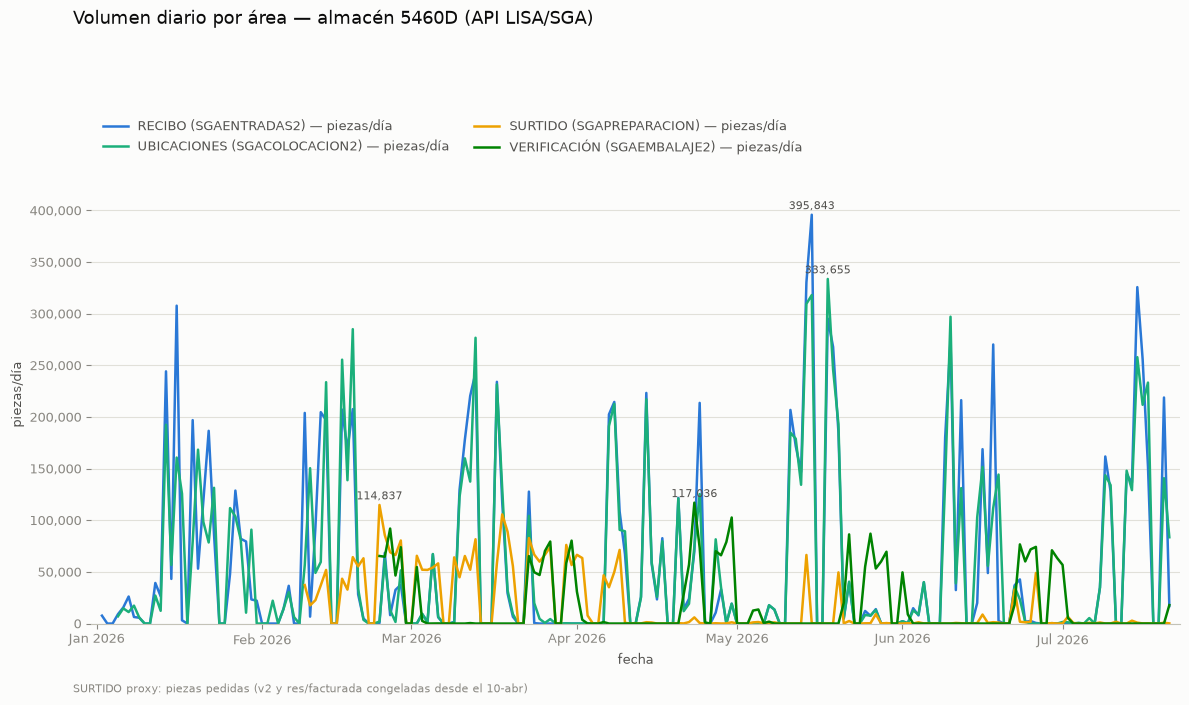

In [6]:
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"

fmt_miles = FuncFormatter(lambda v, _: f"{v:,.0f}")

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

for nombre, a in AREAS.items():
    s = a["serie"]
    ax.plot(
        s.index,
        s.values,
        color=a["color"],
        linewidth=1.8,
        label=f"{nombre} — {a['metrica']}",
    )

    # etiqueta directa del pico de cada serie
    dia_max = s.idxmax()
    ax.annotate(
        f"{int(s.max()):,}",
        xy=(dia_max, s.max()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=INK_2,
    )

maximo = max(a["serie"].max() for a in AREAS.values())
ax.set_ylim(0, maximo * 1.12)
ax.margins(x=0.01)
ax.set_ylabel("piezas/día", fontsize=9, color=INK_2)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(BASELINE)
ax.tick_params(colors=MUTED, labelsize=9)
ax.yaxis.set_major_formatter(fmt_miles)

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_xlabel("fecha", fontsize=9, color=INK_2)

# leyenda encima del área de trazado para no tapar las líneas
ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    ncol=2,
    frameon=False,
    fontsize=9,
    labelcolor=INK_2,
)

notas = "   ·   ".join(
    f"{nombre.split(' ')[0]} {a['nota']}" for nombre, a in AREAS.items() if a["nota"]
)
fig.text(0.065, 0.005, notas, fontsize=8, color=MUTED, ha="left")

fig.suptitle(
    f"Volumen diario por área — almacén {ALMACEN} (API LISA/SGA)",
    fontsize=13,
    color=INK,
    x=0.065,
    ha="left",
)
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
plt.show()